In [ ]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.1/129.1 kB 3.0 MB/s eta 0:00:00


# Importing Libraries

In [ ]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, BatchNormalization, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from keras_tuner.tuners import RandomSearch
from keras_tuner import Objective

# Reproducibility (ensures consistent results)
np.random.seed(42)
tf.random.set_seed(42)

# Class Labels
class_labels = ['Acne', 'Blackheads', 'Dark circles (Puffy Eyes)', 'Hyperpigmentation',
                'Redness', 'Scars', 'Vitiligo', 'Whiteheads', 'Wrinkles']
num_classes = len(class_labels)

# Image dimensions
img_height, img_width = 224, 224  

# Dataset Paths
base_path = 'drive/MyDrive/updated_final_skin_issue_dataset/'
train_dir = os.path.join(base_path, 'train')
val_dir = os.path.join(base_path, 'valid')

# Dataset Loaders
# Images are automatically resized and labeled based on folder names
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir, image_size=(img_height, img_width), label_mode='int', batch_size=32, shuffle=True
)

valid_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir, image_size=(img_height, img_width), label_mode='int', batch_size=32, shuffle=False
)


# For 10 epochs for phase 1 and 2

# MobileNetV2 Model

Trial 10 Complete [00h 01m 17s]
val_accuracy: 0.3936861753463745

Best val_accuracy So Far: 0.5766016840934753
Total elapsed time: 00h 14m 16s

✅ Best Hyperparameters Found:
Dropout Rate: 0.2
Dense Units 1: 640
Dense Units 2: 448
Optimizer: adam
Learning Rate: 0.000382870470449823
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.3635 - loss: 2.0975
Epoch 1: val_accuracy improved from -inf to 0.39276, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 23s 158ms/step - accuracy: 0.3645 - loss: 2.0936 - val_accuracy: 0.3928 - val_loss: 1.7288
Epoch 2/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6055 - loss: 1.1732
Epoch 2: val_accuracy improved from 0.39276 to 0.48097, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.6056 - loss: 1.1723 - val_accuracy: 0.4810 - val_loss: 1.5377
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6864 - loss: 0.9182
Epoch 3: val_accuracy improved from 0.48097 to 0.51161, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.6864 - loss: 0.9182 - val_accuracy: 0.5116 - val_loss: 1.5030
Epoch 4/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7211 - loss: 0.8341
Epoch 4: val_accuracy did not improve from 0.51161
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.7211 - loss: 0.8332 - val_accuracy: 0.5079 - val_loss: 1.5346
Epoch 5/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7603 - loss: 0.7001
Epoch 5: val_accuracy improved from 0.51161 to 0.52646, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.7605 - loss: 0.6997 - val_accuracy: 0.5265 - val_loss: 1.5655
Epoch 6/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7770 - loss: 0.6306
Epoch 6: val_accuracy improved from 0.52646 to 0.54410, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.7774 - loss: 0.6293 - val_accuracy: 0.5441 - val_loss: 1.5805
Epoch 7/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8226 - loss: 0.5115
Epoch 7: val_accuracy improved from 0.54410 to 0.54503, saving model to training_checkpoints/full_pipeline/best_acc.h5


... (5 outputs left out)

85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 66ms/step - accuracy: 0.8175 - loss: 0.5546 - val_accuracy: 0.6017 - val_loss: 1.4723
Epoch 10/10
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8410 - loss: 0.4896
Epoch 10: val_accuracy improved from 0.60167 to 0.62767, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.8410 - loss: 0.4895 - val_accuracy: 0.6277 - val_loss: 1.3872
Restoring model weights from the end of the best epoch: 10.


34/34 ━━━━━━━━━━━━━━━━━━━━ 8s 129ms/step


<Figure size 1200x1200 with 0 Axes>

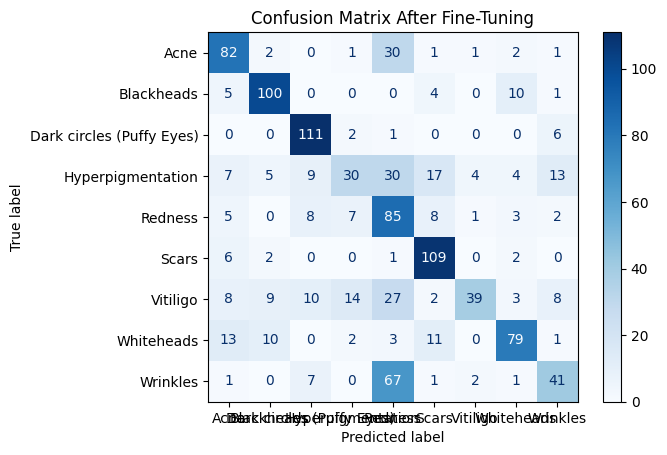


✅ Final Classification Report After Fine-Tuning:
                           precision    recall  f1-score   support

                     Acne       0.65      0.68      0.66       120
               Blackheads       0.78      0.83      0.81       120
Dark circles (Puffy Eyes)       0.77      0.93      0.84       120
        Hyperpigmentation       0.54      0.25      0.34       119
                  Redness       0.35      0.71      0.47       119
                    Scars       0.71      0.91      0.80       120
                 Vitiligo       0.83      0.33      0.47       120
               Whiteheads       0.76      0.66      0.71       119
                 Wrinkles       0.56      0.34      0.42       120

                 accuracy                           0.63      1077
                macro avg       0.66      0.63      0.61      1077
             weighted avg       0.66      0.63      0.61      1077



In [ ]:
# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline', exist_ok=True)
checkpoint = ModelCheckpoint('training_checkpoints/full_pipeline/best_acc.h5', monitor='val_accuracy',
                             save_best_only=True, mode='max', verbose=1)
# Stop training if validation loss does not improve
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
callbacks = [checkpoint, early_stop]

# KerasTuner Model Builder Function
def build_model(hp):
    """
    Builds a MobileNetV2-based classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load pre-trained MobileNetV2 as feature extractor
    base_model = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet',
                                                    input_shape=(img_height, img_width, 3))
    # Freeze backbone initially
    base_model.trainable = False 

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))

    # Feature extraction
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)

    # Tunable dropout
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First dense layer (tunable units)
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second dense layer (tunable units)
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer for multi-class classification
    outputs = Dense(num_classes, activation='softmax')(x)
    # Build model
    model = Model(inputs, outputs)

    # Optimizer selection (tunable)
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(
        optimizer=optimizer, 
        loss='sparse_categorical_crossentropy', 
        metrics=['accuracy']
    )
    return model

# Hyperparameter Tuning using Random Search
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Retrieve Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n  Best Hyperparameters Found:")
print(f"Dropout Rate: {best_hp.get('dropout_rate')}")
print(f"Dense Units 1: {best_hp.get('dense_units_1')}")
print(f"Dense Units 2: {best_hp.get('dense_units_2')}")
print(f"Optimizer: {best_hp.get('optimizer')}")
print(f"Learning Rate: {best_hp.get('learning_rate')}")

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning (Unfreeze MobileNetV2)
print("\n  Starting Phase 2 Fine-Tuning...")
# Unfreeze backbone
best_model.get_layer('mobilenetv2_1.00_224').trainable = True

# Lower learning rate for fine-tuning
fine_tune_lr = 1e-5
optimizer_choice = best_hp.get('optimizer')

if optimizer_choice == 'adam':
    fine_tune_optimizer = Adam(learning_rate=fine_tune_lr)
elif optimizer_choice == 'rmsprop':
    fine_tune_optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    fine_tune_optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(
    optimizer=fine_tune_optimizer, 
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy']
)
fine_tune_history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# True labels from validation dataset
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning")
plt.show()

# Classification Report
print("\n  Final Classification Report After Fine-Tuning:")
print(classification_report(y_true, y_pred, target_names=class_labels))

# Xception Model

Trial 10 Complete [00h 01m 22s]
val_accuracy: 0.3351903557777405

Best val_accuracy So Far: 0.5060352683067322
Total elapsed time: 00h 13m 31s

✅ Best Hyperparameters Found:
Dropout Rate: 0.30000000000000004
Dense Units 1: 256
Dense Units 2: 256
Optimizer: adam
Learning Rate: 0.0005977728042983697
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.2508 - loss: 2.5442
Epoch 1: val_accuracy improved from -inf to 0.32591, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 22s 153ms/step - accuracy: 0.2515 - loss: 2.5409 - val_accuracy: 0.3259 - val_loss: 2.0806
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.4397 - loss: 1.6940
Epoch 2: val_accuracy improved from 0.32591 to 0.43733, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.4400 - loss: 1.6933 - val_accuracy: 0.4373 - val_loss: 1.7192
Epoch 3/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5126 - loss: 1.4891
Epoch 3: val_accuracy improved from 0.43733 to 0.44661, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.5128 - loss: 1.4879 - val_accuracy: 0.4466 - val_loss: 1.6554
Epoch 4/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5604 - loss: 1.3544
Epoch 4: val_accuracy improved from 0.44661 to 0.48561, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.5602 - loss: 1.3534 - val_accuracy: 0.4856 - val_loss: 1.6452
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.6014 - loss: 1.1967
Epoch 5: val_accuracy did not improve from 0.48561
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.6015 - loss: 1.1965 - val_accuracy: 0.4828 - val_loss: 1.5839
Epoch 6/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6075 - loss: 1.1450
Epoch 6: val_accuracy did not improve from 0.48561
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.6076 - loss: 1.1447 - val_accuracy: 0.4717 - val_loss: 1.6425
Epoch 7/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6256 - loss: 1.1138
Epoch 7: val_accuracy did not improve from 0.48561
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.6259 - loss: 1.1125 - val_accuracy: 0.4838 - val_loss: 1.6122
Epoch 8/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.6643 - loss: 0.9897
Epoch 8: val_accuracy improved from 0.48561

85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.6648 - loss: 0.9881 - val_accuracy: 0.4865 - val_loss: 1.6604
Epoch 9/20
82/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.6925 - loss: 0.9053
Epoch 9: val_accuracy improved from 0.48654 to 0.49304, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


... (6 outputs left out)

85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 89ms/step - accuracy: 0.7775 - loss: 0.6777 - val_accuracy: 0.6899 - val_loss: 0.9207
Epoch 10/10
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8023 - loss: 0.6163
Epoch 10: val_accuracy improved from 0.68988 to 0.70659, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - accuracy: 0.8025 - loss: 0.6159 - val_accuracy: 0.7066 - val_loss: 0.8665
Restoring model weights from the end of the best epoch: 10.


34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 114ms/step


<Figure size 1200x1200 with 0 Axes>

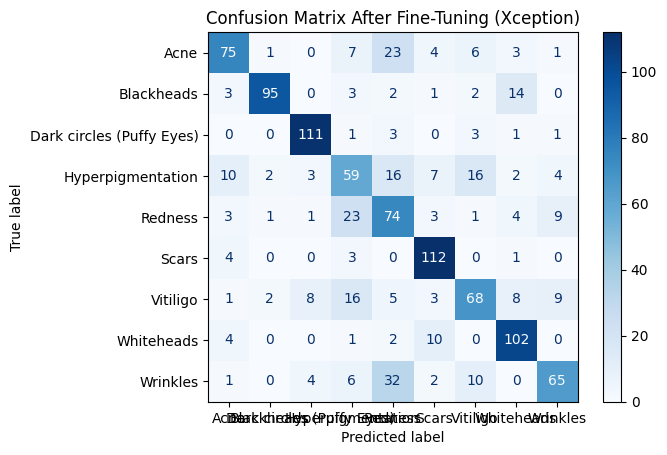


✅ Final Classification Report After Fine-Tuning (Xception):
                           precision    recall  f1-score   support

                     Acne       0.74      0.62      0.68       120
               Blackheads       0.94      0.79      0.86       120
Dark circles (Puffy Eyes)       0.87      0.93      0.90       120
        Hyperpigmentation       0.50      0.50      0.50       119
                  Redness       0.47      0.62      0.54       119
                    Scars       0.79      0.93      0.85       120
                 Vitiligo       0.64      0.57      0.60       120
               Whiteheads       0.76      0.86      0.80       119
                 Wrinkles       0.73      0.54      0.62       120

                 accuracy                           0.71      1077
                macro avg       0.72      0.71      0.71      1077
             weighted avg       0.72      0.71      0.71      1077



In [ ]:
# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline_xception', exist_ok=True)
checkpoint = ModelCheckpoint('training_checkpoints/full_pipeline_xception/best_acc.h5', monitor='val_accuracy',
                             save_best_only=True, mode='max', verbose=1)

# KerasTuner Model Builder Function
def build_model(hp):
    """
    Builds a Xception classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load Xception base model
    base_model = tf.keras.applications.Xception(include_top=False, weights='imagenet',
                                                 input_shape=(img_height, img_width, 3))
    # Freeze base model for transfer learning
    base_model.trainable = False

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))
    x = base_model(inputs, training=False)

    # Feature pooling
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)

    # Tunable dropout
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First Dense Layer
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second Dense Layer
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer
    outputs = Dense(num_classes, activation='softmax')(x)
    model = Model(inputs, outputs)

    # Optimizer tuning
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Hyperparameter Tuning using Random Search
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning_xception',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Retrieve Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n  Best Hyperparameters Found:")
print(f"Dropout Rate: {best_hp.get('dropout_rate')}")
print(f"Dense Units 1: {best_hp.get('dense_units_1')}")
print(f"Dense Units 2: {best_hp.get('dense_units_2')}")
print(f"Optimizer: {best_hp.get('optimizer')}")
print(f"Learning Rate: {best_hp.get('learning_rate')}")

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_xception/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning
print("\n  Starting Phase 2 Fine-Tuning...")
# Unfreeze backbone
best_model.get_layer('xception').trainable = True

# Lower learning rate for fine-tuning
fine_tune_lr = 1e-5
optimizer_choice = best_hp.get('optimizer')

if optimizer_choice == 'adam':
    fine_tune_optimizer = Adam(learning_rate=fine_tune_lr)
elif optimizer_choice == 'rmsprop':
    fine_tune_optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    fine_tune_optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(optimizer=fine_tune_optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_tune_history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_xception/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# True labels from validation dataset
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning (Xception)")
plt.show()

# Classification Report
print("\n  Final Classification Report After Fine-Tuning (Xception):")
print(classification_report(y_true, y_pred, target_names=class_labels))


# EfficientNetB0 Model

Trial 10 Complete [00h 01m 45s]
val_accuracy: 0.6508820652961731

Best val_accuracy So Far: 0.8430826663970947
Total elapsed time: 00h 17m 16s

✅ Best Hyperparameters Found:
Dropout Rate: 0.30000000000000004
Dense Units 1: 256
Dense Units 2: 256
Optimizer: adam
Learning Rate: 0.0005977728042983697
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step - accuracy: 0.4193 - loss: 1.8962
Epoch 1: val_accuracy improved from -inf to 0.67131, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 46s 284ms/step - accuracy: 0.4209 - loss: 1.8902 - val_accuracy: 0.6713 - val_loss: 1.1558
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7573 - loss: 0.7479
Epoch 2: val_accuracy improved from 0.67131 to 0.75395, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.7575 - loss: 0.7470 - val_accuracy: 0.7539 - val_loss: 0.7761
Epoch 3/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8099 - loss: 0.5422
Epoch 3: val_accuracy improved from 0.75395 to 0.77716, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8102 - loss: 0.5417 - val_accuracy: 0.7772 - val_loss: 0.6556
Epoch 4/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8435 - loss: 0.4635
Epoch 4: val_accuracy improved from 0.77716 to 0.79016, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.8437 - loss: 0.4630 - val_accuracy: 0.7902 - val_loss: 0.6251
Epoch 5/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8794 - loss: 0.3716
Epoch 5: val_accuracy improved from 0.79016 to 0.81058, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8795 - loss: 0.3715 - val_accuracy: 0.8106 - val_loss: 0.5805
Epoch 6/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8711 - loss: 0.3683
Epoch 6: val_accuracy improved from 0.81058 to 0.82823, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8714 - loss: 0.3679 - val_accuracy: 0.8282 - val_loss: 0.5489
Epoch 7/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9011 - loss: 0.2730
Epoch 7: val_accuracy did not improve from 0.82823
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9013 - loss: 0.2726 - val_accuracy: 0.8254 - val_loss: 0.5441
Epoch 8/20
82/85 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9165 - loss: 0.2667
Epoch 8: val_accuracy did not improve from 0.82823
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9164 - loss: 0.2664 - val_accuracy: 0.8254 - val_loss: 0.5798
Epoch 9/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9159 - loss: 0.2339
Epoch 9: val_accuracy did not improve from 0.82823
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.9160 - loss: 0.2338 - val_accuracy: 0.8236 - val_loss: 0.5972
Epoch 10/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9308 - loss: 0.2003
Epoch 10: val_accuracy did not improve fro

85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9228 - loss: 0.2191 - val_accuracy: 0.8301 - val_loss: 0.6031
Epoch 12: early stopping
Restoring model weights from the end of the best epoch: 7.



✅ Starting Phase 2 Fine-Tuning...
Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - accuracy: 0.4306 - loss: 2.1204
Epoch 1: val_accuracy did not improve from 0.83008
85/85 ━━━━━━━━━━━━━━━━━━━━ 134s 657ms/step - accuracy: 0.4310 - loss: 2.1184 - val_accuracy: 0.7920 - val_loss: 0.6560
Epoch 2/10
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5361 - loss: 1.5537
Epoch 2: val_accuracy did not improve from 0.83008
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.5366 - loss: 1.5523 - val_accuracy: 0.7279 - val_loss: 0.8577
Epoch 3/10
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.5933 - loss: 1.3400
Epoch 3: val_accuracy did not improve from 0.83008
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.5936 - loss: 1.3388 - val_accuracy: 0.7187 - val_loss: 0.9056
Epoch 4/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.6584 - loss: 1.1395
Epoch 4: val_accuracy did not improve from 0.83008
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.6584 - loss: 1.

34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 215ms/step


<Figure size 1200x1200 with 0 Axes>

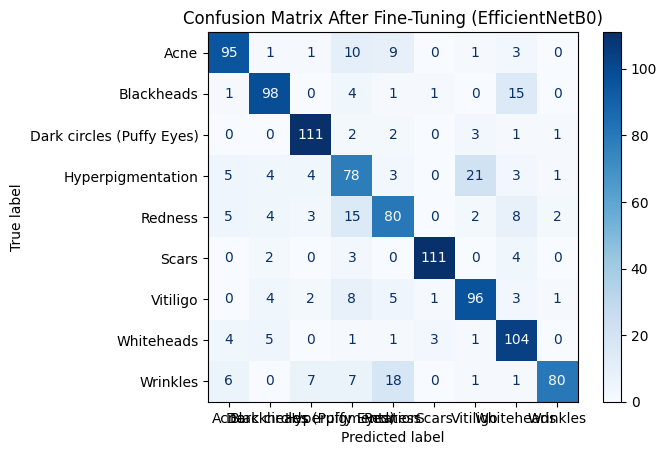


✅ Final Classification Report After Fine-Tuning (EfficientNetB0):
                           precision    recall  f1-score   support

                     Acne       0.82      0.79      0.81       120
               Blackheads       0.83      0.82      0.82       120
Dark circles (Puffy Eyes)       0.87      0.93      0.90       120
        Hyperpigmentation       0.61      0.66      0.63       119
                  Redness       0.67      0.67      0.67       119
                    Scars       0.96      0.93      0.94       120
                 Vitiligo       0.77      0.80      0.78       120
               Whiteheads       0.73      0.87      0.80       119
                 Wrinkles       0.94      0.67      0.78       120

                 accuracy                           0.79      1077
                macro avg       0.80      0.79      0.79      1077
             weighted avg       0.80      0.79      0.79      1077



In [ ]:
# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline_efficientnet', exist_ok=True)

checkpoint = ModelCheckpoint('training_checkpoints/full_pipeline_efficientnet/best_acc.h5', monitor='val_accuracy',
                             save_best_only=True, mode='max', verbose=1)

# KerasTuner Model Builder Function
def build_model(hp):
    """
    Builds a EfficientNetB0 classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load pre-trained EfficientNetB0
    base_model = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                                       input_shape=(img_height, img_width, 3))
    # Freeze backbone initially
    base_model.trainable = False

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))

    # Feature extraction
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)

    # Tunable dropout
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First dense layer
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second dense layer
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer for multi-class classification
    outputs = Dense(num_classes, activation='softmax')(x)
    model = Model(inputs, outputs)

    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')

     # Optimizer selection
    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Hyperparameter Tuning
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning_efficientnet',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n  Best Hyperparameters Found:")
print(f"Dropout Rate: {best_hp.get('dropout_rate')}")
print(f"Dense Units 1: {best_hp.get('dense_units_1')}")
print(f"Dense Units 2: {best_hp.get('dense_units_2')}")
print(f"Optimizer: {best_hp.get('optimizer')}")
print(f"Learning Rate: {best_hp.get('learning_rate')}")

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_efficientnet/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning (Unfreeze EfficientNetB0)
print("\n  Starting Phase 2 Fine-Tuning...")
best_model.get_layer('efficientnetb0').trainable = True

# Lower learning rate for fine-tuning
fine_tune_lr = 1e-5
optimizer_choice = best_hp.get('optimizer')
if optimizer_choice == 'adam':
    fine_tune_optimizer = Adam(learning_rate=fine_tune_lr)
elif optimizer_choice == 'rmsprop':
    fine_tune_optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    fine_tune_optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(optimizer=fine_tune_optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_tune_history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_efficientnet/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# True labels from validation dataset
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning (EfficientNetB0)")
plt.show()

# Classification Report
print("\n  Final Classification Report After Fine-Tuning (EfficientNetB0):")
print(classification_report(y_true, y_pred, target_names=class_labels))


# ResNet50 Model

Trial 10 Complete [00h 01m 33s]
val_accuracy: 0.6360260248184204

Best val_accuracy So Far: 0.8059424161911011
Total elapsed time: 00h 14m 56s

✅ Best Hyperparameters Found:
Dropout Rate: 0.4
Dense Units 1: 768
Dense Units 2: 512
Optimizer: adam
Learning Rate: 0.0008547485565344062
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.5234 - loss: 1.6760
Epoch 1: val_accuracy improved from -inf to 0.69824, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 28s 180ms/step - accuracy: 0.5251 - loss: 1.6693 - val_accuracy: 0.6982 - val_loss: 0.8691
Epoch 2/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8110 - loss: 0.5884
Epoch 2: val_accuracy improved from 0.69824 to 0.76787, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.8117 - loss: 0.5859 - val_accuracy: 0.7679 - val_loss: 0.7270
Epoch 3/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8651 - loss: 0.3811
Epoch 3: val_accuracy improved from 0.76787 to 0.78644, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.8655 - loss: 0.3801 - val_accuracy: 0.7864 - val_loss: 0.7373
Epoch 4/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.8993 - loss: 0.3238
Epoch 4: val_accuracy improved from 0.78644 to 0.80409, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.8994 - loss: 0.3235 - val_accuracy: 0.8041 - val_loss: 0.7498
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9094 - loss: 0.2563
Epoch 5: val_accuracy did not improve from 0.80409
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9094 - loss: 0.2563 - val_accuracy: 0.7697 - val_loss: 0.9486
Epoch 6/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9254 - loss: 0.2115
Epoch 6: val_accuracy did not improve from 0.80409
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9256 - loss: 0.2112 - val_accuracy: 0.8013 - val_loss: 0.8065
Epoch 7/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9293 - loss: 0.2101
Epoch 7: val_accuracy did not improve from 0.80409
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9296 - loss: 0.2089 - val_accuracy: 0.8032 - val_loss: 0.7395
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.



✅ Starting Phase 2 Fine-Tuning...
Epoch 1/10
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - accuracy: 0.7292 - loss: 0.9020
Epoch 1: val_accuracy did not improve from 0.80409
85/85 ━━━━━━━━━━━━━━━━━━━━ 91s 408ms/step - accuracy: 0.7298 - loss: 0.9002 - val_accuracy: 0.7669 - val_loss: 0.7887
Epoch 2/10
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8439 - loss: 0.4721
Epoch 2: val_accuracy improved from 0.80409 to 0.80687, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


... (4 outputs left out)

85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - accuracy: 0.9525 - loss: 0.1263 - val_accuracy: 0.8654 - val_loss: 0.4788
Epoch 8/10
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9651 - loss: 0.0947
Epoch 8: val_accuracy did not improve from 0.86537
85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.9652 - loss: 0.0946 - val_accuracy: 0.8617 - val_loss: 0.4874
Epoch 9/10
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.9692 - loss: 0.0948
Epoch 9: val_accuracy improved from 0.86537 to 0.87465, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 88ms/step - accuracy: 0.9693 - loss: 0.0945 - val_accuracy: 0.8747 - val_loss: 0.4521
Epoch 10/10
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9731 - loss: 0.0942
Epoch 10: val_accuracy did not improve from 0.87465
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - accuracy: 0.9731 - loss: 0.0939 - val_accuracy: 0.8691 - val_loss: 0.4450
Restoring model weights from the end of the best epoch: 10.


34/34 ━━━━━━━━━━━━━━━━━━━━ 9s 148ms/step


<Figure size 1200x1200 with 0 Axes>

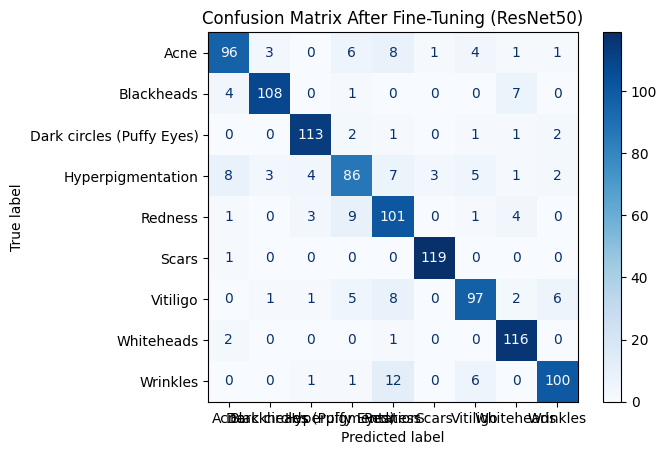


✅ Final Classification Report After Fine-Tuning (ResNet50):
                           precision    recall  f1-score   support

                     Acne       0.86      0.80      0.83       120
               Blackheads       0.94      0.90      0.92       120
Dark circles (Puffy Eyes)       0.93      0.94      0.93       120
        Hyperpigmentation       0.78      0.72      0.75       119
                  Redness       0.73      0.85      0.79       119
                    Scars       0.97      0.99      0.98       120
                 Vitiligo       0.85      0.81      0.83       120
               Whiteheads       0.88      0.97      0.92       119
                 Wrinkles       0.90      0.83      0.87       120

                 accuracy                           0.87      1077
                macro avg       0.87      0.87      0.87      1077
             weighted avg       0.87      0.87      0.87      1077



In [ ]:
# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline_resnet', exist_ok=True)

checkpoint = ModelCheckpoint('training_checkpoints/full_pipeline_resnet/best_acc.h5', monitor='val_accuracy',
                             save_best_only=True, mode='max', verbose=1)
# Stop training if validation loss does not improve
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
callbacks = [checkpoint, early_stop]

# ResNet50 HyperModel
def build_model(hp):
    """
    Builds a ResNet50-based classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load pre-trained ResNet50
    base_model = tf.keras.applications.ResNet50(include_top=False, weights='imagenet',
                                                 input_shape=(img_height, img_width, 3))
    # Freeze backbone initially
    base_model.trainable = False

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))
    # Feature extraction
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)

    # Tunable dropout
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First dense layer 
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second dense layer 
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer 
    outputs = Dense(num_classes, activation='softmax')(x)

    # Build model
    model = Model(inputs, outputs)

    # Optimizer selection
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(
        optimizer=optimizer, 
        loss='sparse_categorical_crossentropy', 
        metrics=['accuracy']
    )
    return model

# Hyperparameter Tuning
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning_resnet',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Retrieve Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n  Best Hyperparameters Found:")
print(f"Dropout Rate: {best_hp.get('dropout_rate')}")
print(f"Dense Units 1: {best_hp.get('dense_units_1')}")
print(f"Dense Units 2: {best_hp.get('dense_units_2')}")
print(f"Optimizer: {best_hp.get('optimizer')}")
print(f"Learning Rate: {best_hp.get('learning_rate')}")

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_resnet/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning
print("\n  Starting Phase 2 Fine-Tuning...")
# Unfreeze backbone
best_model.get_layer('resnet50').trainable = True

# Lower learning rate for fine-tuning
fine_tune_lr = 1e-5
optimizer_choice = best_hp.get('optimizer')
if optimizer_choice == 'adam':
    fine_tune_optimizer = Adam(learning_rate=fine_tune_lr)
elif optimizer_choice == 'rmsprop':
    fine_tune_optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    fine_tune_optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(
    optimizer=fine_tune_optimizer, 
    loss='sparse_categorical_crossentropy', 
    metrics=['accuracy']
)
fine_tune_history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_resnet/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# True labels from validation dataset
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning (ResNet50)")
plt.show()

# Classification Report
print("\n  Final Classification Report After Fine-Tuning (ResNet50):")
print(classification_report(y_true, y_pred, target_names=class_labels))

# For 20 epochs for phase 1 and 2

In [ ]:
# Importing Libraries
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, BatchNormalization, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from keras_tuner.tuners import RandomSearch
from keras_tuner import Objective

#   Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

#   Class Labels
class_labels = ['Acne', 'Blackheads', 'Dark circles (Puffy Eyes)', 'Hyperpigmentation',
                'Redness', 'Scars', 'Vitiligo', 'Whiteheads', 'Wrinkles']
num_classes = len(class_labels)

#   Image dimensions
img_height, img_width = 224, 224 

#   Dataset Paths
base_path = 'drive/MyDrive/updated_final_skin_issue_dataset/'
train_dir = os.path.join(base_path, 'train')
val_dir = os.path.join(base_path, 'valid')

#   Dataset Loaders
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir, image_size=(img_height, img_width), label_mode='int', batch_size=32, shuffle=True
)

valid_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir, image_size=(img_height, img_width), label_mode='int', batch_size=32, shuffle=False
)

# MobileNetV2 Model

Found 2699 files belonging to 9 classes.
Found 1077 files belonging to 9 classes.
Reloading Tuner from keras_tuner_search/skin_issue_tuning/tuner0.json

✅ Best Hyperparameters Found:
Dropout Rate: 0.2
Dense Units 1: 640
Dense Units 2: 448
Optimizer: adam
Learning Rate: 0.000382870470449823
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.3460 - loss: 2.1129
Epoch 1: val_accuracy improved from -inf to 0.42897, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 24s 162ms/step - accuracy: 0.3470 - loss: 2.1094 - val_accuracy: 0.4290 - val_loss: 1.6577
Epoch 2/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6205 - loss: 1.1377
Epoch 2: val_accuracy improved from 0.42897 to 0.46797, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.6207 - loss: 1.1372 - val_accuracy: 0.4680 - val_loss: 1.5782
Epoch 3/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.6710 - loss: 0.9503
Epoch 3: val_accuracy improved from 0.46797 to 0.49118, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.6712 - loss: 0.9496 - val_accuracy: 0.4912 - val_loss: 1.5574
Epoch 4/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7341 - loss: 0.7938
Epoch 4: val_accuracy improved from 0.49118 to 0.50139, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.7342 - loss: 0.7934 - val_accuracy: 0.5014 - val_loss: 1.5612
Epoch 5/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.7592 - loss: 0.7128
Epoch 5: val_accuracy improved from 0.50139 to 0.52925, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.7597 - loss: 0.7112 - val_accuracy: 0.5292 - val_loss: 1.5604
Epoch 6/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7943 - loss: 0.5674
Epoch 6: val_accuracy improved from 0.52925 to 0.53668, saving model to training_checkpoints/full_pipeline/best_acc.h5


... (15 outputs left out)

85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.9352 - loss: 0.2144 - val_accuracy: 0.7567 - val_loss: 0.8066
Epoch 20/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9247 - loss: 0.2331
Epoch 20: val_accuracy improved from 0.75673 to 0.77159, saving model to training_checkpoints/full_pipeline/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.9250 - loss: 0.2324 - val_accuracy: 0.7716 - val_loss: 0.7699
Restoring model weights from the end of the best epoch: 20.


34/34 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step


<Figure size 1200x1200 with 0 Axes>

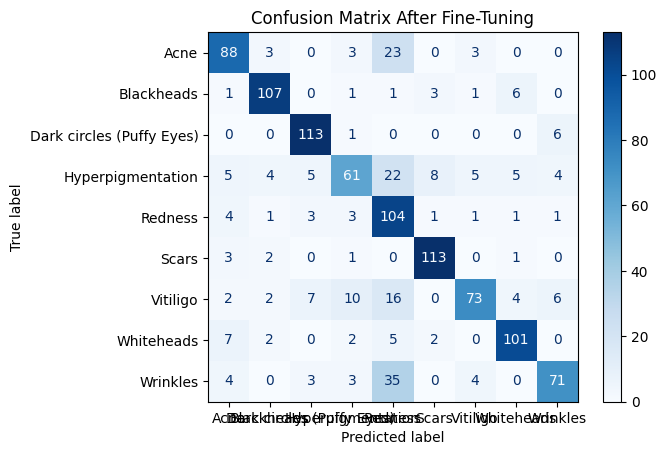


✅ Final Classification Report After Fine-Tuning:
                           precision    recall  f1-score   support

                     Acne       0.77      0.73      0.75       120
               Blackheads       0.88      0.89      0.89       120
Dark circles (Puffy Eyes)       0.86      0.94      0.90       120
        Hyperpigmentation       0.72      0.51      0.60       119
                  Redness       0.50      0.87      0.64       119
                    Scars       0.89      0.94      0.91       120
                 Vitiligo       0.84      0.61      0.71       120
               Whiteheads       0.86      0.85      0.85       119
                 Wrinkles       0.81      0.59      0.68       120

                 accuracy                           0.77      1077
                macro avg       0.79      0.77      0.77      1077
             weighted avg       0.79      0.77      0.77      1077



In [ ]:
# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline', exist_ok=True)
checkpoint = ModelCheckpoint('training_checkpoints/full_pipeline/best_acc.h5', monitor='val_accuracy',
                             save_best_only=True, mode='max', verbose=1)

# Stop training if validation loss does not improve
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
callbacks = [checkpoint, early_stop]

# KerasTuner Model Builder Function
def build_model(hp):
    """
    Builds a MobileNetV2-based classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load pre-trained MobileNetV2 as feature extractor
    base_model = tf.keras.applications.MobileNetV2(include_top=False, weights='imagenet',
                                                    input_shape=(img_height, img_width, 3))
    # Freeze backbone initially
    base_model.trainable = False

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))
    # Feature extraction
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)

    # Tunable dropout
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First dense layer
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second dense layer
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer for multi-class classification
    outputs = Dense(num_classes, activation='softmax')(x)
    # Build model
    model = Model(inputs, outputs)

    # Optimizer selection
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Hyperparameter Tuning
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Retrieve Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n  Best Hyperparameters Found:")
print(f"Dropout Rate: {best_hp.get('dropout_rate')}")
print(f"Dense Units 1: {best_hp.get('dense_units_1')}")
print(f"Dense Units 2: {best_hp.get('dense_units_2')}")
print(f"Optimizer: {best_hp.get('optimizer')}")
print(f"Learning Rate: {best_hp.get('learning_rate')}")

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning (Unfreeze MobileNetV2)
print("\n  Starting Phase 2 Fine-Tuning...")
# Unfreeze backbone
best_model.get_layer('mobilenetv2_1.00_224').trainable = True

fine_tune_lr = 1e-5
optimizer_choice = best_hp.get('optimizer')
if optimizer_choice == 'adam':
    fine_tune_optimizer = Adam(learning_rate=fine_tune_lr)
elif optimizer_choice == 'rmsprop':
    fine_tune_optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    fine_tune_optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(optimizer=fine_tune_optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_tune_history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)
# True labels from validation dataset
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning")
plt.show()

# Classification Report
print("\n  Final Classification Report After Fine-Tuning:")
print(classification_report(y_true, y_pred, target_names=class_labels))


# Xception Model

Found 2699 files belonging to 9 classes.
Found 1077 files belonging to 9 classes.
Reloading Tuner from keras_tuner_search/skin_issue_tuning_xception/tuner0.json

✅ Best Hyperparameters Found:
Dropout Rate: 0.30000000000000004
Dense Units 1: 256
Dense Units 2: 256
Optimizer: adam
Learning Rate: 0.0005977728042983697
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.2638 - loss: 2.4880
Epoch 1: val_accuracy improved from -inf to 0.32683, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 23s 158ms/step - accuracy: 0.2646 - loss: 2.4849 - val_accuracy: 0.3268 - val_loss: 2.1831
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.4541 - loss: 1.6723
Epoch 2: val_accuracy improved from 0.32683 to 0.43175, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - accuracy: 0.4540 - loss: 1.6721 - val_accuracy: 0.4318 - val_loss: 1.7856
Epoch 3/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.5195 - loss: 1.4574
Epoch 3: val_accuracy improved from 0.43175 to 0.45032, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - accuracy: 0.5197 - loss: 1.4568 - val_accuracy: 0.4503 - val_loss: 1.6868
Epoch 4/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5230 - loss: 1.3917
Epoch 4: val_accuracy improved from 0.45032 to 0.46425, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.5235 - loss: 1.3901 - val_accuracy: 0.4643 - val_loss: 1.6369
Epoch 5/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.5850 - loss: 1.2085
Epoch 5: val_accuracy improved from 0.46425 to 0.46982, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.5855 - loss: 1.2074 - val_accuracy: 0.4698 - val_loss: 1.6531
Epoch 6/20
82/85 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.6368 - loss: 1.1088
Epoch 6: val_accuracy improved from 0.46982 to 0.47632, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


... (17 outputs left out)

85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 99ms/step - accuracy: 0.9118 - loss: 0.3022 - val_accuracy: 0.7911 - val_loss: 0.6485
Epoch 19/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9119 - loss: 0.2968
Epoch 19: val_accuracy did not improve from 0.79109
85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 87ms/step - accuracy: 0.9121 - loss: 0.2960 - val_accuracy: 0.7911 - val_loss: 0.6367
Epoch 20/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.9281 - loss: 0.2633
Epoch 20: val_accuracy improved from 0.79109 to 0.80037, saving model to training_checkpoints/full_pipeline_xception/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step - accuracy: 0.9280 - loss: 0.2632 - val_accuracy: 0.8004 - val_loss: 0.6192
Restoring model weights from the end of the best epoch: 20.


34/34 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step


<Figure size 1200x1200 with 0 Axes>

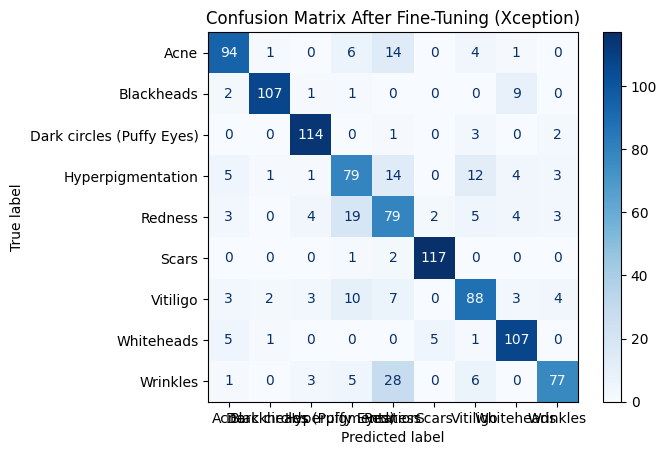


✅ Final Classification Report After Fine-Tuning (Xception):
                           precision    recall  f1-score   support

                     Acne       0.83      0.78      0.81       120
               Blackheads       0.96      0.89      0.92       120
Dark circles (Puffy Eyes)       0.90      0.95      0.93       120
        Hyperpigmentation       0.65      0.66      0.66       119
                  Redness       0.54      0.66      0.60       119
                    Scars       0.94      0.97      0.96       120
                 Vitiligo       0.74      0.73      0.74       120
               Whiteheads       0.84      0.90      0.87       119
                 Wrinkles       0.87      0.64      0.74       120

                 accuracy                           0.80      1077
                macro avg       0.81      0.80      0.80      1077
             weighted avg       0.81      0.80      0.80      1077



In [ ]:
# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline_xception', exist_ok=True)

checkpoint = ModelCheckpoint('training_checkpoints/full_pipeline_xception/best_acc.h5', monitor='val_accuracy',
                             save_best_only=True, mode='max', verbose=1)
# Stop training if validation loss does not improve
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
callbacks = [checkpoint, early_stop]

# KerasTuner Model Builder Function
def build_model(hp):
    """
    Builds a Xception-based classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load pre-trained Xception as feature extractor
    base_model = tf.keras.applications.Xception(include_top=False, weights='imagenet',
                                                 input_shape=(img_height, img_width, 3))
    # Freeze backbone initially
    base_model.trainable = False

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))
    # Feature extraction
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)

    # Tunable dropout
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First dense layer
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second dense layer
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer for multi-class classification
    outputs = Dense(num_classes, activation='softmax')(x)
    # Build model
    model = Model(inputs, outputs)

    # Optimizer selection
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Hyperparameter Tuning using Random Search
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning_xception',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Retrieve Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n  Best Hyperparameters Found:")
print(f"Dropout Rate: {best_hp.get('dropout_rate')}")
print(f"Dense Units 1: {best_hp.get('dense_units_1')}")
print(f"Dense Units 2: {best_hp.get('dense_units_2')}")
print(f"Optimizer: {best_hp.get('optimizer')}")
print(f"Learning Rate: {best_hp.get('learning_rate')}")

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_xception/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning
print("\n  Starting Phase 2 Fine-Tuning...")
# Unfreeze backbone
best_model.get_layer('xception').trainable = True

# Lower learning rate for fine-tuning
fine_tune_lr = 1e-5
optimizer_choice = best_hp.get('optimizer')
if optimizer_choice == 'adam':
    fine_tune_optimizer = Adam(learning_rate=fine_tune_lr)
elif optimizer_choice == 'rmsprop':
    fine_tune_optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    fine_tune_optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(optimizer=fine_tune_optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_tune_history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_xception/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# True labels from validation dataset
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning (Xception)")
plt.show()

# Classification Report
print("\n  Final Classification Report After Fine-Tuning (Xception):")
print(classification_report(y_true, y_pred, target_names=class_labels))


# EfficientNetB0 Model

Found 2699 files belonging to 9 classes.
Found 1077 files belonging to 9 classes.
Reloading Tuner from keras_tuner_search/skin_issue_tuning_efficientnet/tuner0.json

✅ Best Hyperparameters Found:
Dropout Rate: 0.2
Dense Units 1: 640
Dense Units 2: 448
Optimizer: adam
Learning Rate: 0.000382870470449823
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.5306 - loss: 1.5594
Epoch 1: val_accuracy improved from -inf to 0.70195, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 48s 300ms/step - accuracy: 0.5322 - loss: 1.5535 - val_accuracy: 0.7019 - val_loss: 1.0295
Epoch 2/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8533 - loss: 0.4505
Epoch 2: val_accuracy improved from 0.70195 to 0.74095, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.8534 - loss: 0.4498 - val_accuracy: 0.7409 - val_loss: 0.7627
Epoch 3/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9015 - loss: 0.2950
Epoch 3: val_accuracy improved from 0.74095 to 0.76695, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.9015 - loss: 0.2949 - val_accuracy: 0.7669 - val_loss: 0.6837
Epoch 4/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9239 - loss: 0.2539
Epoch 4: val_accuracy improved from 0.76695 to 0.78737, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 62ms/step - accuracy: 0.9239 - loss: 0.2535 - val_accuracy: 0.7874 - val_loss: 0.6595
Epoch 5/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9396 - loss: 0.1765
Epoch 5: val_accuracy did not improve from 0.78737
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9397 - loss: 0.1767 - val_accuracy: 0.7855 - val_loss: 0.6780
Epoch 6/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9487 - loss: 0.1457
Epoch 6: val_accuracy improved from 0.78737 to 0.81894, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.9489 - loss: 0.1457 - val_accuracy: 0.8189 - val_loss: 0.6604
Epoch 7/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9478 - loss: 0.1529
Epoch 7: val_accuracy improved from 0.81894 to 0.82637, saving model to training_checkpoints/full_pipeline_efficientnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.9479 - loss: 0.1528 - val_accuracy: 0.8264 - val_loss: 0.6291
Epoch 8/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9529 - loss: 0.1211
Epoch 8: val_accuracy did not improve from 0.82637
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9531 - loss: 0.1209 - val_accuracy: 0.8050 - val_loss: 0.7222
Epoch 9/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9581 - loss: 0.1117
Epoch 9: val_accuracy did not improve from 0.82637
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9582 - loss: 0.1115 - val_accuracy: 0.8227 - val_loss: 0.7074
Epoch 10/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9636 - loss: 0.1033
Epoch 10: val_accuracy did not improve from 0.82637
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.9636 - loss: 0.1033 - val_accuracy: 0.8264 - val_loss: 0.6822
Epoch 11/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9645 - loss: 0.1030
Epoch 11: val_accuracy did not improve f

85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.9722 - loss: 0.0959 - val_accuracy: 0.8301 - val_loss: 0.7177
Epoch 12: early stopping
Restoring model weights from the end of the best epoch: 7.



✅ Starting Phase 2 Fine-Tuning...
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.5043 - loss: 1.8233
Epoch 1: val_accuracy did not improve from 0.83008
85/85 ━━━━━━━━━━━━━━━━━━━━ 116s 541ms/step - accuracy: 0.5046 - loss: 1.8220 - val_accuracy: 0.7957 - val_loss: 0.7104
Epoch 2/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.6093 - loss: 1.3092
Epoch 2: val_accuracy did not improve from 0.83008
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 58ms/step - accuracy: 0.6095 - loss: 1.3085 - val_accuracy: 0.7419 - val_loss: 0.9099
Epoch 3/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.6509 - loss: 1.1584
Epoch 3: val_accuracy did not improve from 0.83008
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.6511 - loss: 1.1575 - val_accuracy: 0.7270 - val_loss: 0.9544
Epoch 4/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.7326 - loss: 0.8738
Epoch 4: val_accuracy did not improve from 0.83008
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.7327 - loss: 0.

34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 214ms/step


<Figure size 1200x1200 with 0 Axes>

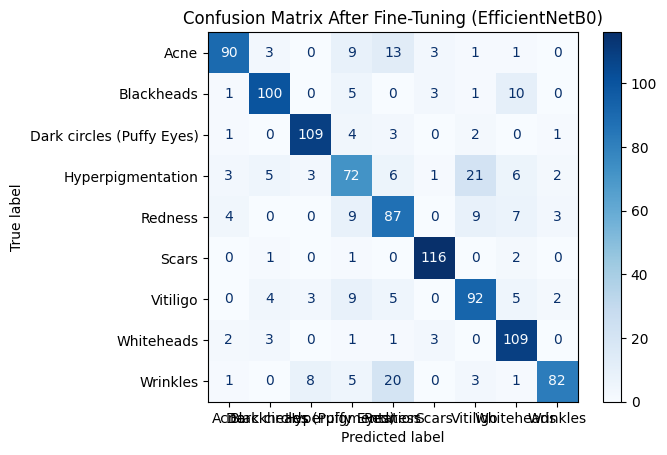


✅ Final Classification Report After Fine-Tuning (EfficientNetB0):
                           precision    recall  f1-score   support

                     Acne       0.88      0.75      0.81       120
               Blackheads       0.86      0.83      0.85       120
Dark circles (Puffy Eyes)       0.89      0.91      0.90       120
        Hyperpigmentation       0.63      0.61      0.62       119
                  Redness       0.64      0.73      0.69       119
                    Scars       0.92      0.97      0.94       120
                 Vitiligo       0.71      0.77      0.74       120
               Whiteheads       0.77      0.92      0.84       119
                 Wrinkles       0.91      0.68      0.78       120

                 accuracy                           0.80      1077
                macro avg       0.80      0.80      0.80      1077
             weighted avg       0.80      0.80      0.80      1077



In [ ]:
# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline_efficientnet', exist_ok=True)

checkpoint = ModelCheckpoint('training_checkpoints/full_pipeline_efficientnet/best_acc.h5', monitor='val_accuracy',
                             save_best_only=True, mode='max', verbose=1)
# Stop training if validation loss does not improve
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
callbacks = [checkpoint, early_stop]

# HyperModel using EfficientNetB0
def build_model(hp):
    """
    Builds a EfficientNetB0-based classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load pre-trained EfficientNetB0
    base_model = tf.keras.applications.EfficientNetB0(include_top=False, weights='imagenet',
                                                       input_shape=(img_height, img_width, 3))
    # Freeze backbone initially
    base_model.trainable = False

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))
    # Feature extraction
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)

    # Tunable dropout
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First dense layer
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second dense layer
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer
    outputs = Dense(num_classes, activation='softmax')(x)
    # Build model
    model = Model(inputs, outputs)

    # Optimizer selection 
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Hyperparameter Tuning using Random Search
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning_efficientnet',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Retrieve Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n  Best Hyperparameters Found:")
print(f"Dropout Rate: {best_hp.get('dropout_rate')}")
print(f"Dense Units 1: {best_hp.get('dense_units_1')}")
print(f"Dense Units 2: {best_hp.get('dense_units_2')}")
print(f"Optimizer: {best_hp.get('optimizer')}")
print(f"Learning Rate: {best_hp.get('learning_rate')}")

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_efficientnet/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning
print("\n  Starting Phase 2 Fine-Tuning...")
# Unfreeze backbone
best_model.get_layer('efficientnetb0').trainable = True

# Lower learning rate for fine-tuning
fine_tune_lr = 1e-5
optimizer_choice = best_hp.get('optimizer')
if optimizer_choice == 'adam':
    fine_tune_optimizer = Adam(learning_rate=fine_tune_lr)
elif optimizer_choice == 'rmsprop':
    fine_tune_optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    fine_tune_optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(optimizer=fine_tune_optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_tune_history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=20, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_efficientnet/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)
# True labels from validation dataset
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning (EfficientNetB0)")
plt.show()

# Classification Report
print("\n  Final Classification Report After Fine-Tuning (EfficientNetB0):")
print(classification_report(y_true, y_pred, target_names=class_labels))


# ResNet50 Model

Trial 10 Complete [00h 01m 28s]
val_accuracy: 0.6453110575675964

Best val_accuracy So Far: 0.8161559700965881
Total elapsed time: 00h 15m 35s

✅ Best Hyperparameters Found:
Dropout Rate: 0.30000000000000004
Dense Units 1: 256
Dense Units 2: 256
Optimizer: adam
Learning Rate: 0.0005977728042983697
Epoch 1/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.4659 - loss: 1.7671
Epoch 1: val_accuracy improved from -inf to 0.66667, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 27s 175ms/step - accuracy: 0.4677 - loss: 1.7611 - val_accuracy: 0.6667 - val_loss: 0.9886
Epoch 2/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8046 - loss: 0.5962
Epoch 2: val_accuracy improved from 0.66667 to 0.73630, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 64ms/step - accuracy: 0.8049 - loss: 0.5948 - val_accuracy: 0.7363 - val_loss: 0.8084
Epoch 3/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8619 - loss: 0.4171
Epoch 3: val_accuracy improved from 0.73630 to 0.76509, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8619 - loss: 0.4169 - val_accuracy: 0.7651 - val_loss: 0.7241
Epoch 4/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8939 - loss: 0.3327
Epoch 4: val_accuracy improved from 0.76509 to 0.78644, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.8939 - loss: 0.3323 - val_accuracy: 0.7864 - val_loss: 0.6859
Epoch 5/20
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9035 - loss: 0.2731
Epoch 5: val_accuracy did not improve from 0.78644
85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 56ms/step - accuracy: 0.9036 - loss: 0.2729 - val_accuracy: 0.7846 - val_loss: 0.7405
Epoch 6/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9300 - loss: 0.1926
Epoch 6: val_accuracy improved from 0.78644 to 0.79109, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.9299 - loss: 0.1927 - val_accuracy: 0.7911 - val_loss: 0.7308
Epoch 7/20
83/85 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9349 - loss: 0.1988
Epoch 7: val_accuracy improved from 0.79109 to 0.80037, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


... (14 outputs left out)

85/85 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step - accuracy: 0.9888 - loss: 0.0382 - val_accuracy: 0.8812 - val_loss: 0.3809
Epoch 18/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9879 - loss: 0.0465
Epoch 18: val_accuracy did not improve from 0.88115
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.9880 - loss: 0.0462 - val_accuracy: 0.8784 - val_loss: 0.3947
Epoch 19/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.9969 - loss: 0.0267
Epoch 19: val_accuracy did not improve from 0.88115
85/85 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - accuracy: 0.9969 - loss: 0.0267 - val_accuracy: 0.8774 - val_loss: 0.3982
Epoch 20/20
84/85 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9952 - loss: 0.0254
Epoch 20: val_accuracy improved from 0.88115 to 0.88487, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 87ms/step - accuracy: 0.9952 - loss: 0.0255 - val_accuracy: 0.8849 - val_loss: 0.3820
Restoring model weights from the end of the best epoch: 17.


34/34 ━━━━━━━━━━━━━━━━━━━━ 9s 144ms/step


<Figure size 1200x1200 with 0 Axes>

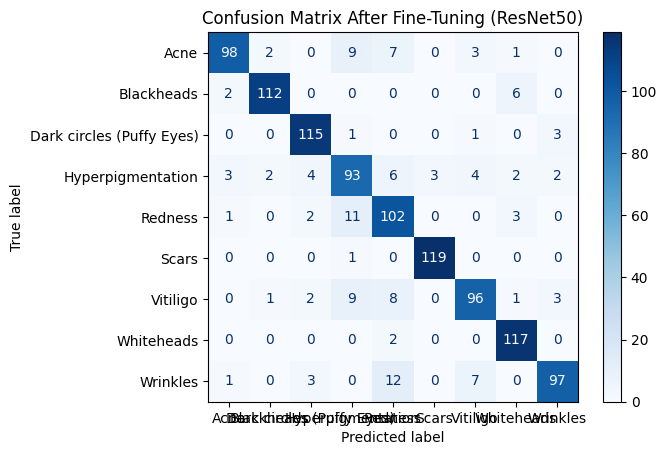


✅ Final Classification Report After Fine-Tuning (ResNet50):
                           precision    recall  f1-score   support

                     Acne       0.93      0.82      0.87       120
               Blackheads       0.96      0.93      0.95       120
Dark circles (Puffy Eyes)       0.91      0.96      0.93       120
        Hyperpigmentation       0.75      0.78      0.77       119
                  Redness       0.74      0.86      0.80       119
                    Scars       0.98      0.99      0.98       120
                 Vitiligo       0.86      0.80      0.83       120
               Whiteheads       0.90      0.98      0.94       119
                 Wrinkles       0.92      0.81      0.86       120

                 accuracy                           0.88      1077
                macro avg       0.88      0.88      0.88      1077
             weighted avg       0.88      0.88      0.88      1077



In [ ]:
# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline_resnet', exist_ok=True)

checkpoint = ModelCheckpoint(
    'training_checkpoints/full_pipeline_resnet/best_acc.h5', 
    monitor='val_accuracy',
    save_best_only=True, 
    mode='max', 
    verbose=1
)
# Stop training if validation loss does not improve
early_stop = EarlyStopping(
    monitor='val_loss', 
    patience=5, 
    restore_best_weights=True, 
    verbose=1
)
callbacks = [checkpoint, early_stop]

# ResNet50 HyperModel
def build_model(hp):
    """
    Builds a ResNet50-based classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load pre-trained ResNet50 as feature extractor
    base_model = tf.keras.applications.ResNet50(include_top=False, weights='imagenet',
                                                 input_shape=(img_height, img_width, 3))
    # Freeze backbone initially
    base_model.trainable = False

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))
    x = base_model(inputs, training=False)

    # Using Batch Normalization and Tunable Dropout
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First dense layer 
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second dense layer
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer for multi-class classification
    outputs = Dense(num_classes, activation='softmax')(x)

    # Build model
    model = Model(inputs, outputs)

    # Optimizer selection 
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(
        optimizer=optimizer, 
        loss='sparse_categorical_crossentropy', 
        metrics=['accuracy']
    )
    return model

# Hyperparameter Tuning using Random Search
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning_resnet',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Retrieve Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\n  Best Hyperparameters Found:")
print(f"Dropout Rate: {best_hp.get('dropout_rate')}")
print(f"Dense Units 1: {best_hp.get('dense_units_1')}")
print(f"Dense Units 2: {best_hp.get('dense_units_2')}")
print(f"Optimizer: {best_hp.get('optimizer')}")
print(f"Learning Rate: {best_hp.get('learning_rate')}")

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(
    train_dataset, 
    validation_data=valid_dataset, 
    epochs=20, 
    callbacks=callbacks
    )
best_model.save('training_checkpoints/full_pipeline_resnet/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning 
print("\n  Starting Phase 2 Fine-Tuning...")
# Unfreeze backbone
best_model.get_layer('resnet50').trainable = True

# Lower learning rate for fine-tuning
fine_tune_lr = 1e-5
optimizer_choice = best_hp.get('optimizer')
if optimizer_choice == 'adam':
    fine_tune_optimizer = Adam(learning_rate=fine_tune_lr)
elif optimizer_choice == 'rmsprop':
    fine_tune_optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    fine_tune_optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(optimizer=fine_tune_optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_tune_history = best_model.fit(
    train_dataset, 
    validation_data=valid_dataset, 
    epochs=20, 
    callbacks=callbacks
)
best_model.save('training_checkpoints/full_pipeline_resnet/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)

# True labels from validation dataset
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning (ResNet50)")
plt.show()

# Classification Report
print("\n  Final Classification Report After Fine-Tuning (ResNet50):")
print(classification_report(y_true, y_pred, target_names=class_labels))


# Updated Code for ResNet50 for Vitiligo Problem

Trial 10 Complete [00h 06m 05s]
val_accuracy: 0.6833797693252563

Best val_accuracy So Far: 0.8217270374298096
Total elapsed time: 01h 01m 41s
Epoch 1/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.5943 - loss: 1.3552
Epoch 1: val_accuracy improved from -inf to 0.72888, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 54s 494ms/step - accuracy: 0.5957 - loss: 1.3503 - val_accuracy: 0.7289 - val_loss: 0.7847
Epoch 2/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.8487 - loss: 0.4675
Epoch 2: val_accuracy improved from 0.72888 to 0.77159, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 391ms/step - accuracy: 0.8487 - loss: 0.4674 - val_accuracy: 0.7716 - val_loss: 0.7098
Epoch 3/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.8740 - loss: 0.3916
Epoch 3: val_accuracy did not improve from 0.77159
85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 381ms/step - accuracy: 0.8740 - loss: 0.3915 - val_accuracy: 0.7586 - val_loss: 0.7649
Epoch 4/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.8984 - loss: 0.3153
Epoch 4: val_accuracy improved from 0.77159 to 0.77530, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 390ms/step - accuracy: 0.8983 - loss: 0.3152 - val_accuracy: 0.7753 - val_loss: 0.8143
Epoch 5/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step - accuracy: 0.9099 - loss: 0.2781
Epoch 5: val_accuracy improved from 0.77530 to 0.78087, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 388ms/step - accuracy: 0.9099 - loss: 0.2779 - val_accuracy: 0.7809 - val_loss: 0.7883
Epoch 6/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.9146 - loss: 0.2370
Epoch 6: val_accuracy improved from 0.78087 to 0.79016, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 389ms/step - accuracy: 0.9146 - loss: 0.2370 - val_accuracy: 0.7902 - val_loss: 0.8745
Epoch 7/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 365ms/step - accuracy: 0.9163 - loss: 0.2399
Epoch 7: val_accuracy did not improve from 0.79016
85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 382ms/step - accuracy: 0.9164 - loss: 0.2395 - val_accuracy: 0.7772 - val_loss: 0.8678
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.


... (12 outputs left out)

85/85 ━━━━━━━━━━━━━━━━━━━━ 34s 401ms/step - accuracy: 0.9910 - loss: 0.0351 - val_accuracy: 0.8923 - val_loss: 0.3795
Epoch 22/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 0.9902 - loss: 0.0345
Epoch 22: val_accuracy improved from 0.89229 to 0.89694, saving model to training_checkpoints/full_pipeline_resnet/best_acc.h5


85/85 ━━━━━━━━━━━━━━━━━━━━ 35s 402ms/step - accuracy: 0.9902 - loss: 0.0346 - val_accuracy: 0.8969 - val_loss: 0.3773
Epoch 23/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.9935 - loss: 0.0248
Epoch 23: val_accuracy did not improve from 0.89694
85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 387ms/step - accuracy: 0.9935 - loss: 0.0249 - val_accuracy: 0.8877 - val_loss: 0.4217
Epoch 24/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - accuracy: 0.9852 - loss: 0.0397
Epoch 24: val_accuracy did not improve from 0.89694
85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 385ms/step - accuracy: 0.9852 - loss: 0.0397 - val_accuracy: 0.8877 - val_loss: 0.4191
Epoch 25/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step - accuracy: 0.9927 - loss: 0.0294
Epoch 25: val_accuracy did not improve from 0.89694
85/85 ━━━━━━━━━━━━━━━━━━━━ 33s 384ms/step - accuracy: 0.9927 - loss: 0.0294 - val_accuracy: 0.8960 - val_loss: 0.4133
Epoch 26/30
85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 369ms/step - accuracy: 0.9883 - loss: 0.0341
Epoch 26: val_accuracy d

34/34 ━━━━━━━━━━━━━━━━━━━━ 9s 147ms/step


<Figure size 1200x1200 with 0 Axes>

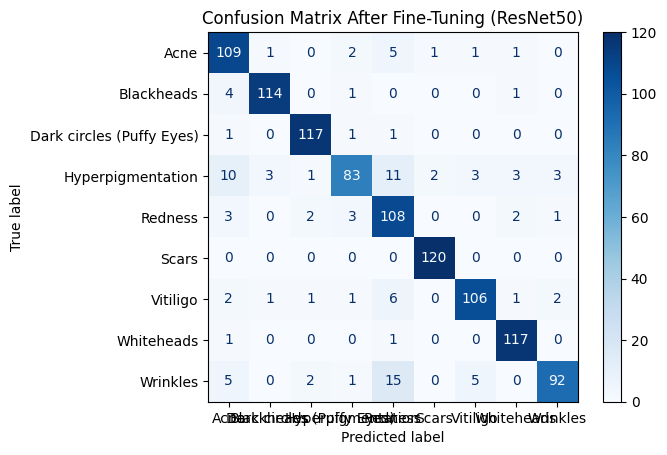


✅ Final Classification Report:
                           precision    recall  f1-score   support

                     Acne       0.81      0.91      0.85       120
               Blackheads       0.96      0.95      0.95       120
Dark circles (Puffy Eyes)       0.95      0.97      0.96       120
        Hyperpigmentation       0.90      0.70      0.79       119
                  Redness       0.73      0.91      0.81       119
                    Scars       0.98      1.00      0.99       120
                 Vitiligo       0.92      0.88      0.90       120
               Whiteheads       0.94      0.98      0.96       119
                 Wrinkles       0.94      0.77      0.84       120

                 accuracy                           0.90      1077
                macro avg       0.90      0.90      0.90      1077
             weighted avg       0.90      0.90      0.90      1077



In [ ]:
# Importing libraries
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, BatchNormalization, Dense, Dropout
from tensorflow.keras.optimizers import Adam, RMSprop, SGD
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from keras_tuner.tuners import RandomSearch
from keras_tuner import Objective

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Class Labels
class_labels = ['Acne', 'Blackheads', 'Dark circles (Puffy Eyes)', 'Hyperpigmentation',
                'Redness', 'Scars', 'Vitiligo', 'Whiteheads', 'Wrinkles']
num_classes = len(class_labels)
img_height, img_width = 224, 224

# Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

# Load Datasets
AUTOTUNE = tf.data.AUTOTUNE
base_path = 'drive/MyDrive/updated_final_skin_issue_dataset/'
train_dir = os.path.join(base_path, 'train')
val_dir = os.path.join(base_path, 'valid')

train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir, image_size=(img_height, img_width), label_mode='int', batch_size=32, shuffle=True
).map(lambda x, y: (data_augmentation(x, training=True), y)).prefetch(buffer_size=AUTOTUNE)

valid_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    val_dir, image_size=(img_height, img_width), label_mode='int', batch_size=32, shuffle=False
).prefetch(buffer_size=AUTOTUNE)

# Callbacks for Training Control
# Save best model based on validation accuracy
os.makedirs('training_checkpoints/full_pipeline_resnet', exist_ok=True)
checkpoint = ModelCheckpoint('training_checkpoints/full_pipeline_resnet/best_acc.h5', monitor='val_accuracy',
                             save_best_only=True, mode='max', verbose=1)
# Stop training if validation loss does not improve
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
callbacks = [checkpoint, early_stop]

# ResNet50 HyperModel
def build_model(hp):
    """
    Builds a ResNet50-based classification model with
    tunable hyperparameters using KerasTuner.
    """
    # Load pre-trained ResNet50 as feature extractor
    base_model = tf.keras.applications.ResNet50(include_top=False, weights='imagenet',
                                                 input_shape=(img_height, img_width, 3))
    # Freeze backbone initially
    base_model.trainable = False

    # Model input
    inputs = Input(shape=(img_height, img_width, 3))
    # Feature extraction
    x = base_model(inputs, training=False)
    x = GlobalAveragePooling2D()(x)
    x = BatchNormalization()(x)

    # Tunable dropout
    dropout_rate = hp.Float('dropout_rate', 0.2, 0.5, step=0.1)
    x = Dropout(dropout_rate)(x)

    # First dense layer 
    dense_1 = hp.Int('dense_units_1', 256, 1024, step=128)
    x = Dense(dense_1, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Second dense layer
    dense_2 = hp.Int('dense_units_2', 128, 512, step=64)
    x = Dense(dense_2, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(dropout_rate)(x)

    # Output layer for multi-class classification
    outputs = Dense(num_classes, activation='softmax')(x)
    # Build model
    model = Model(inputs, outputs)

    # Optimizer selection 
    lr = hp.Float('learning_rate', 1e-5, 1e-3, sampling='log')
    optimizer_choice = hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd'])

    if optimizer_choice == 'adam':
        optimizer = Adam(learning_rate=lr)
    elif optimizer_choice == 'rmsprop':
        optimizer = RMSprop(learning_rate=lr)
    else:
        optimizer = SGD(learning_rate=lr, momentum=0.9)

    # Compile model
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

# Hyperparameter Tuning using Random Search
tuner = RandomSearch(
    build_model,
    objective=Objective('val_accuracy', direction='max'),
    max_trials=10,
    directory='keras_tuner_search',
    project_name='skin_issue_tuning_resnet',
    seed=42
)

# Run hyperparameter search
tuner.search(train_dataset, validation_data=valid_dataset, epochs=10, callbacks=callbacks)

# Retrieve Best Hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]

# Phase 1: Training with Frozen Backbone
best_model = tuner.hypermodel.build(best_hp)
history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=30, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_resnet/tuned_frozen_model.h5')

# Phase 2: Fine-Tuning
print("\n  Fine-Tuning ResNet50 Base...")
# Unfreeze backbone
best_model.get_layer('resnet50').trainable = True

# Lower learning rate for fine-tuning
fine_tune_lr = 1e-5
opt_choice = best_hp.get('optimizer')
if opt_choice == 'adam':
    optimizer = Adam(learning_rate=fine_tune_lr)
elif opt_choice == 'rmsprop':
    optimizer = RMSprop(learning_rate=fine_tune_lr)
else:
    optimizer = SGD(learning_rate=fine_tune_lr, momentum=0.9)

best_model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_tune_history = best_model.fit(train_dataset, validation_data=valid_dataset, epochs=30, callbacks=callbacks)
best_model.save('training_checkpoints/full_pipeline_resnet/tuned_finetuned_model.h5')

# Model Evaluation
predictions = best_model.predict(valid_dataset, verbose=1)
y_pred = np.argmax(predictions, axis=1)
y_true = np.concatenate([y for x, y in valid_dataset], axis=0)

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(12, 12))
ConfusionMatrixDisplay(cm, display_labels=class_labels).plot(cmap='Blues')
plt.title("Confusion Matrix After Fine-Tuning (ResNet50)")
plt.show()

# Classification Report
print("\n  Final Classification Report:")
print(classification_report(y_true, y_pred, target_names=class_labels))
